Diffusion Models

This is an important topic because diffusion models are behind many modern image-generation systems, including Stable Diffusion.

We'll build the concept from scratch and connect it to GANs and VAEs.

## 1. What are Diffusion Models?

A diffusion model is a generative model that learns to generate data by reversing a gradual noise-addition process.

Let's take an image of a car.

Imagine that we progressively add random noise to the image until it becomes completely unrecognizable.

Initially:

- The image is clear.
- We add a little noise.
- We add more noise.
- Eventually, the image becomes almost entirely random noise.

Now imagine training a neural network to reverse this process.

It starts with random noise and progressively removes the noise until a meaningful image emerges.

**That's the fundamental idea behind diffusion models.**

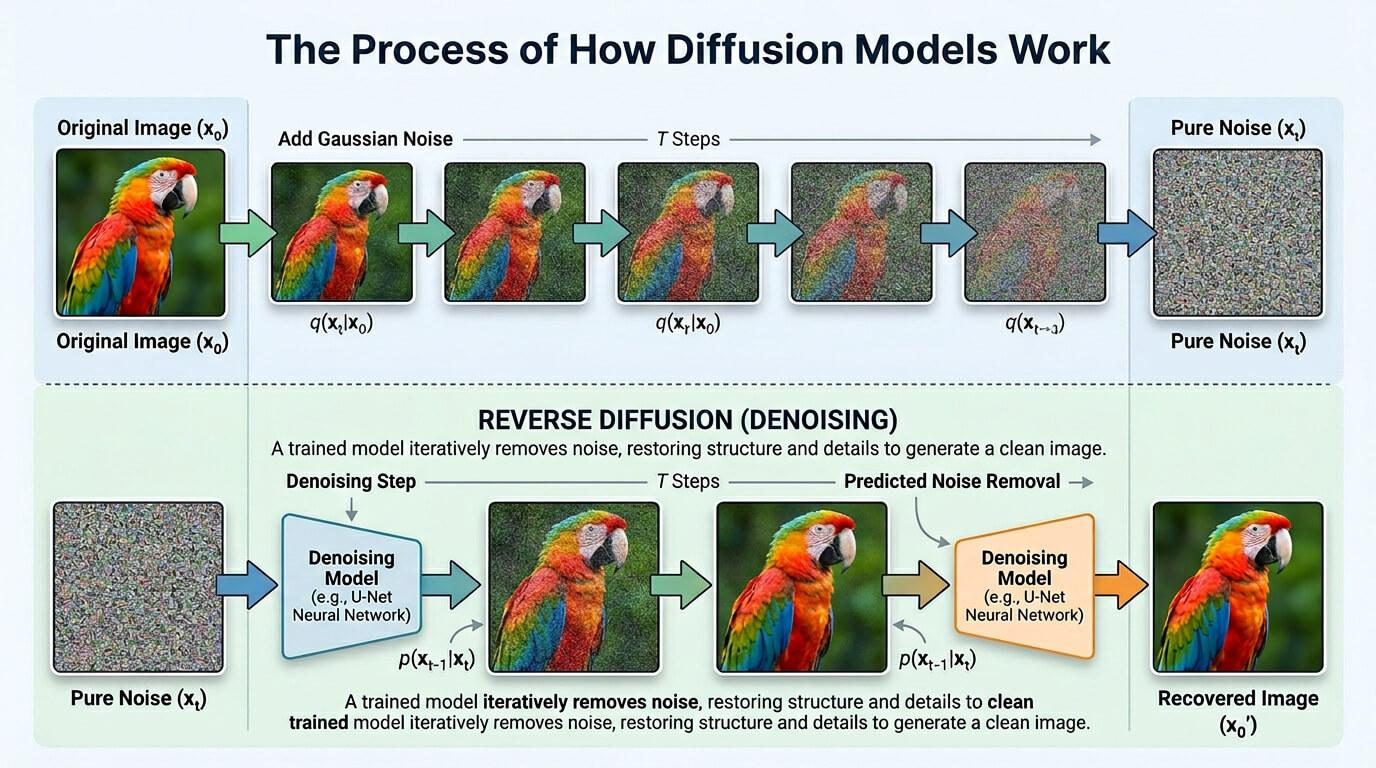

There are two processes:

1. Forward diffusion: Gradually add noise to real data.
2. Reverse diffusion: Gradually remove noise to generate data.

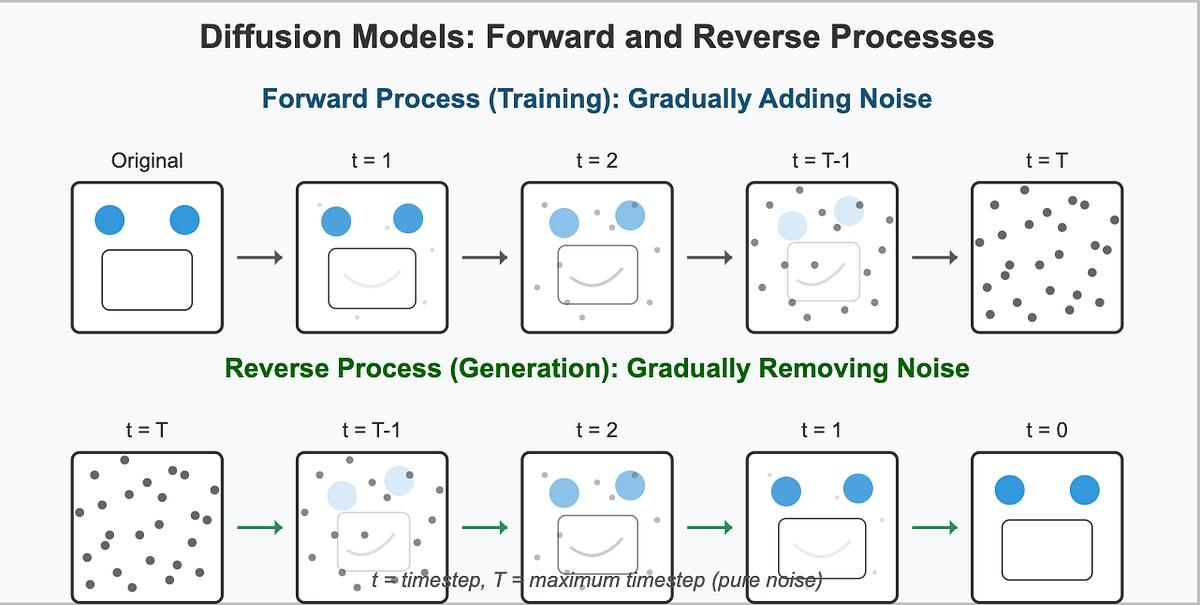

# 2. Forward Diffusion Process

Suppose we have a training dataset containing 50,000 images of cars.

We select one real image.

Let's call it:

\[
x_0
\]

Here, \(x_0\) represents the original, clean image.

Our objective is to gradually add Gaussian noise to this image.

### Step 1: Add a small amount of noise

We add a little random noise.

\[
x_0 \rightarrow x_1
\]

The image is still recognizable.

### Step 2: Add more noise

\[
x_1 \rightarrow x_2
\]

The image becomes less recognizable.

### Step 3: Continue adding noise

\[
x_2 \rightarrow x_3 \rightarrow ... \rightarrow x_T
\]

Eventually, after many steps, the original image becomes almost indistinguishable from random Gaussian noise.

The complete process looks like this:



### Why do we add noise?

This is an important question.

We are deliberately destroying the original image because we want to train a neural network to learn how to reverse that destruction.

The model needs to learn:

- What does a noisy image look like?
- What noise was added?
- How can that noise be removed?
- How can the original image structure be recovered?

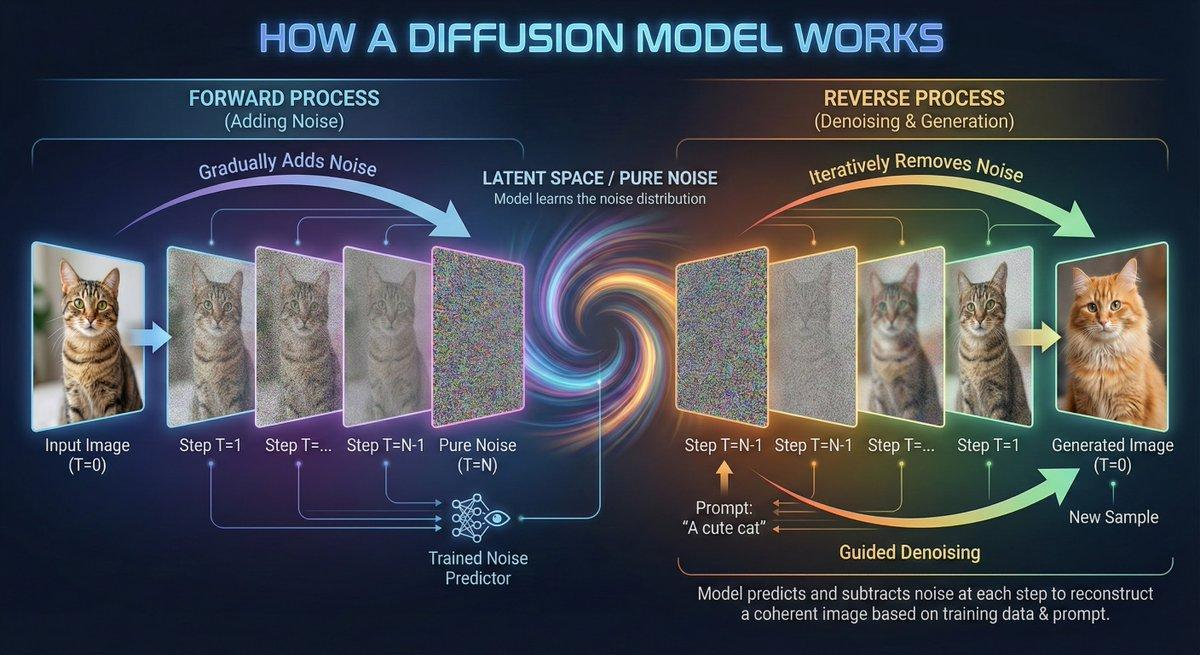

### Mathematical understanding

The forward diffusion process is commonly defined as:

\[
q(x_t|x_{t-1}) =
\mathcal{N}(x_t;\sqrt{1-\beta_t}x_{t-1},\beta_t I)
\]

Don't get intimidated by the equation.

Let's understand its components.

| Component | Meaning |
|---|---|
| \(x_t\) | Image at current timestep |
| \(x_{t-1}\) | Image at previous timestep |
| \(\beta_t\) | Amount of noise added |
| \(\mathcal{N}\) | Gaussian probability distribution |
| \(I\) | Identity matrix |

The value of \(\beta_t\) controls how much noise is introduced at each step.

As we move forward, the image becomes progressively noisier.

**Important:** The forward diffusion process is generally predefined using a noise schedule. We don't train a neural network to add noise.

---

# 3. Reverse Diffusion Process

Now comes the interesting part.

We have an image that has been gradually converted into random noise.

Our objective is to recover a meaningful image.

We train a neural network to predict the noise present in the noisy image.

The network learns to estimate the noise added at each timestep.

Let's understand this with an example.

Suppose the original image is:

```text
Original image: A car
```

After adding noise:

```text
Noisy image: Car + random Gaussian noise
```

The neural network receives the noisy image and predicts:

```text
Predicted noise: Estimated Gaussian noise
```

We use this prediction to remove some noise and obtain a cleaner image.

We repeat this process over multiple timesteps.

Eventually:

```text
Random noise
     |
     v
  Denoising
     |
     v
  Denoising
     |
     v
  Denoising
     |
     v
 Generated car image
```



### One important distinction

The model does not simply take a noisy image and directly produce the original image in one operation.

It learns to predict the noise at a particular timestep, and that prediction is used to calculate a less noisy sample.

This happens repeatedly.

---

# 4. How is the Diffusion Model Trained?

Let's assume we have 100,000 training images.

The training process looks like this:

**Step 1: Select a real image**

Take one image from the training dataset.

\[
x_0
\]

**Step 2: Randomly select a timestep**

For example, select timestep 500 out of 1,000.

**Step 3: Add noise**

Generate random Gaussian noise and add it to the original image according to the noise schedule.

We obtain:

\[
x_{500}
\]

**Step 4: Pass the noisy image to the neural network**

The model receives:

- Noisy image.
- Timestep information.

It predicts the noise.

**Step 5: Calculate the loss**

We already know the actual noise that we added.

Therefore, we compare:

- Actual noise.
- Predicted noise.

A common training objective is:

\[
L = \mathbb{E}_{x_0,\epsilon,t}
\left[
\|\epsilon-\epsilon_\theta(x_t,t)\|^2
\right]
\]

Where:

- \(\epsilon\) = Actual noise.
- \(\epsilon_\theta\) = Predicted noise.
- \(x_t\) = Noisy image.
- \(t\) = Timestep.
- \(\theta\) = Neural network parameters.

The objective is to minimize the difference between actual and predicted noise.

**Step 6: Backpropagation**

The loss is backpropagated through the neural network.

Its weights are updated to improve noise prediction.

This process is repeated across training images and timesteps.

### Important observation

Unlike GANs, diffusion models don't need a competing Discriminator.

Unlike traditional VAEs, their primary training objective is not to reconstruct the input through an encoder-decoder architecture.

They learn to reverse a noise process.

---

# 5. What Neural Network is Used for Denoising?

A common architecture used in diffusion models is U-Net.

remember U-Net from your CNN and image segmentation topics?

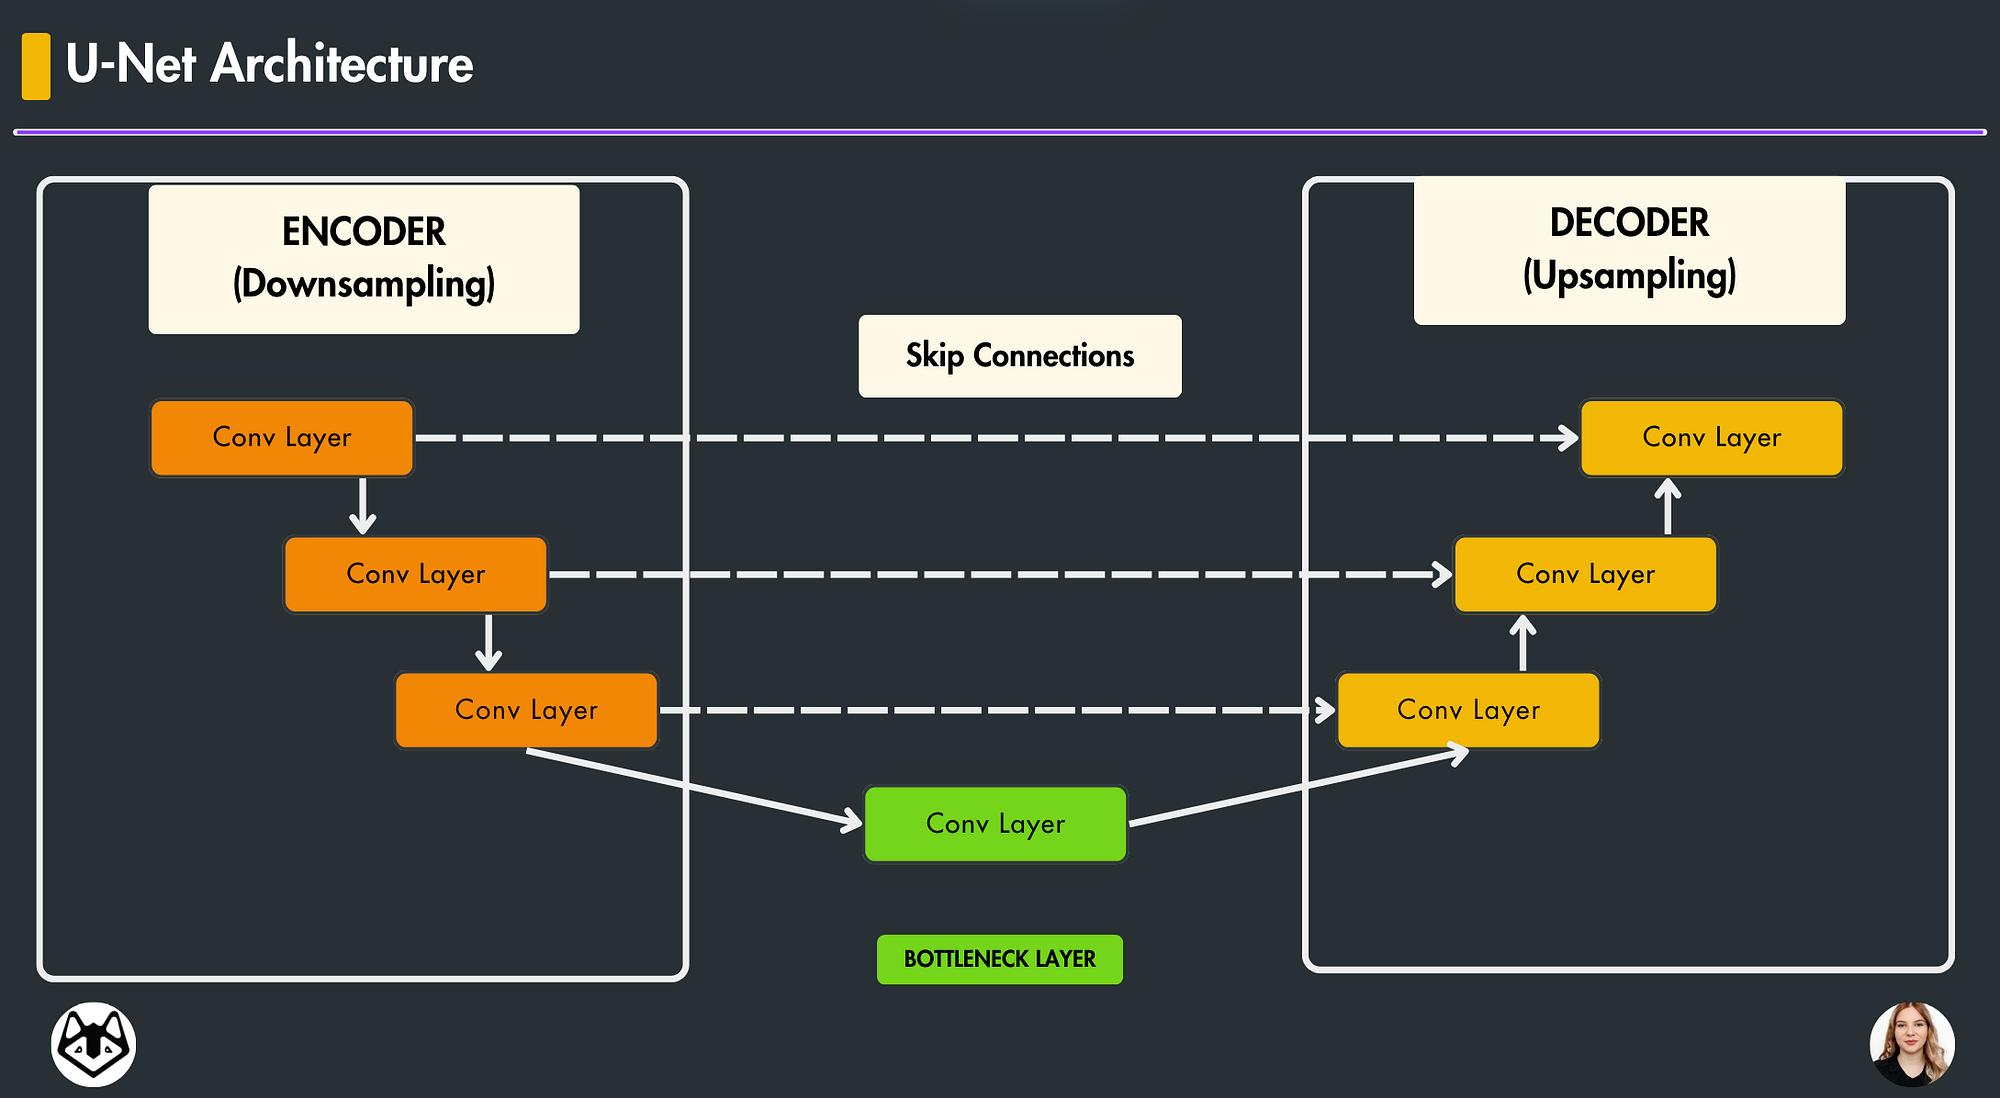

U-Net contains:

- Encoder/downsampling path.
- Bottleneck.
- Decoder/upsampling path.
- Skip connections.

Why is it useful?

Because it captures information at different spatial resolutions.

The encoder learns broader contextual information, while the decoder reconstructs spatial details.

Skip connections help preserve important image information.

In diffusion models, U-Net is commonly used to predict the noise present in the noisy image.

The model also receives timestep information because the amount of noise differs at different stages.

---

# 6. How does Text-to-Image Generation Work?

Now let's connect this to Stable Diffusion.

Suppose you enter:

"Generate a red sports car parked on a beach during sunset."

How does the system generate this image?

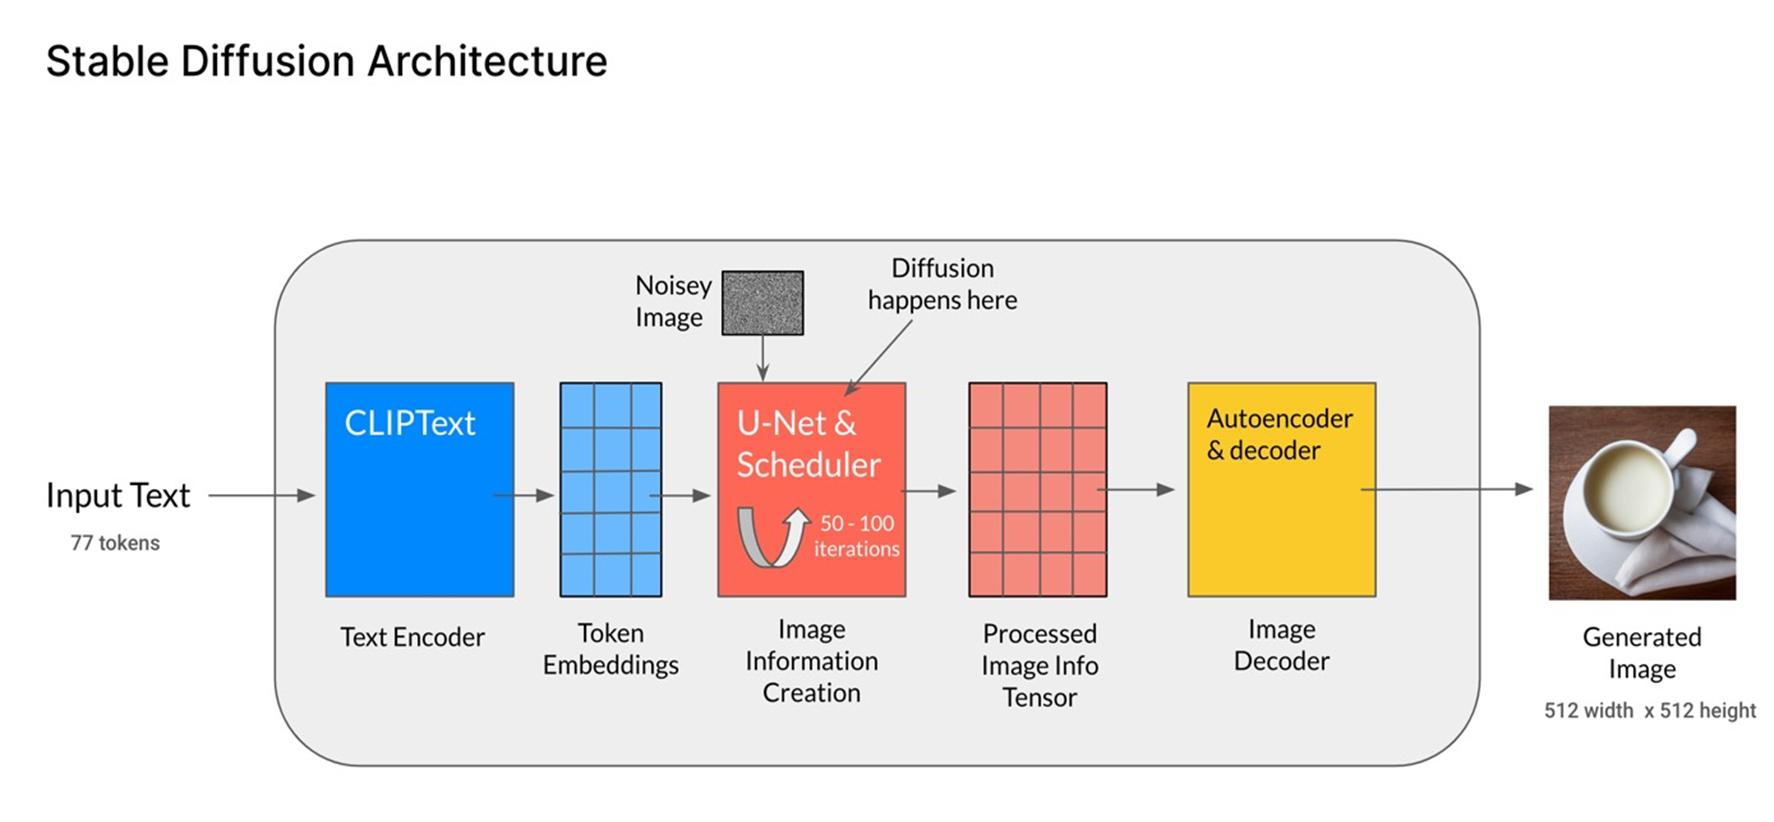

The simplified process is:

### Step 1: Text encoding

The prompt is converted into numerical representations using a text encoder.

These representations capture the semantic meaning of the prompt.

### Step 2: Initial noise generation

The system starts with random noise in the image's latent space.

### Step 3: Denoising

The denoising network progressively removes noise.

However, it doesn't operate independently.

It receives the text representation as conditioning information.

This helps guide the generation process towards the requested concept.

### Step 4: Repeated denoising

The model performs multiple denoising steps.

The noisy representation gradually becomes a meaningful image representation.

### Step 5: Image decoding

In latent diffusion systems such as Stable Diffusion, the final latent representation is decoded into an image using a VAE decoder.

The resulting image is returned to the user.

**Notice the connection?**

GANs, VAEs and diffusion models are not necessarily isolated technologies.

Modern generative architectures can combine different concepts.

---

# 7. What is Latent Diffusion?

This is another important concept.

Generating images directly in pixel space can be computationally expensive.

For example:

An image of 512 × 512 pixels contains 262,144 spatial positions per channel.

Instead of performing the entire diffusion process on the original image, latent diffusion models first compress the image into a lower-dimensional latent representation using a trained VAE encoder.

The diffusion process then happens in this compressed latent space.

Finally, the VAE decoder converts the generated latent representation back into an image.

The architecture looks like this:

```text
         Original Image
                |
                v
          VAE Encoder
                |
                v
        Compressed Latent
                |
                v
       Diffusion Process
                |
                v
       Denoised Latent
                |
                v
          VAE Decoder
                |
                v
         Generated Image
```

This is the fundamental idea behind Latent Diffusion Models.

It reduces computational requirements compared with performing diffusion directly in pixel space.

---

# 8. GAN vs VAE vs Diffusion

Let's consolidate all three.

| Feature | GAN | VAE | Diffusion |
|---|---|---|---|
| Main architecture | Generator + Discriminator | Encoder + Decoder | Noise prediction network |
| Training objective | Adversarial loss | Reconstruction + KL divergence | Noise prediction loss |
| Generation input | Random noise | Random latent sample | Random noise |
| Generation mechanism | Direct generation | Latent decoding | Iterative denoising |
| Training challenge | Adversarial instability | Reconstruction-quality trade-off | Computational cost |
| Image quality | Often sharp | Traditional versions may be blurry | Often highly detailed |
| Examples | StyleGAN | Vanilla VAE | Stable Diffusion |

### Interview-ready answer

"Diffusion models are generative models that learn to generate data by reversing a gradual noise-addition process. During training, Gaussian noise is progressively added to real training samples, and a neural network learns to predict the noise at different timesteps. During inference, the model starts with random noise and repeatedly performs denoising steps to generate a meaningful sample. Unlike GANs, diffusion models don't use an adversarial Generator-Discriminator setup. They generally provide high-quality generation but can require multiple denoising steps, making generation computationally expensive."

---

# 9. Check your understanding

**Q1.** During diffusion model training, we take a real image, add random noise and ask the neural network to predict that noise.

Why don't we directly train the neural network to predict the original clean image instead?

**Q2.** Suppose we trained a diffusion model on 100,000 vehicle images.

During inference, we provide random noise.

How does the model know whether to generate a car, truck or motorcycle if we haven't provided any text prompt?

**Q3.** In Stable Diffusion, why do we use a VAE encoder and decoder along with a diffusion model? What problem does latent diffusion solve?

Once these are clear, we've completed Day 26.

**Next: Day 27 – Stable Diffusion, DALL-E, Image Generation, Video Generation, Audio Generation and Multimodal GenAI.**